# Part 12: The Same Screen on Parts 2b, 4 and 5

Part 11 gave Part 2 the 30-dataset treatment and two more of its claims fell. It also found *why*:
Part 2's quantities split into two groups an order of magnitude apart in dataset-to-dataset
variation, and both of the claims that failed rested on the high-variation group — **extreme-value
statistics**, the minimum ESS over a run and the maximum gap over a run, which varied by 37–82%
across datasets where the time-averaged quantities varied by 3–11%.

Three parts of this repo were built on the same single-dataset design and have not been screened:

| part | design | what has already been error-barred |
|---|---|---|
| **Part 2b** (`rho(F) = 1`) | `DATA_SEED = 42`, 10 filter seeds | Part 3b did the relative gaps and the long-horizon flatness |
| **Part 4** (Student-`t` noise) | `DATA_SEED = 42`, 10–200 **filter** seeds | one 12-dataset check, on the `y* = 20` likelihood probe only |
| **Part 5** (`rho(F)` sweep) | `DATA_SEED = 42`, 8 filter seeds | one 30-dataset check, on the relative gap only |

Many filter seeds on one dataset is precisely the design Part 11 showed averages away the wrong
noise: it removes the filter's Monte Carlo error and leaves the dataset's contribution untouched.
Part 4 is the clearest case — 200 seeds in one section, all on dataset 42.

### The screen is a prediction, not a fishing trip

Part 11's finding is specific enough to bet on, so the bets are written down in Section 1 **before**
any of them are run, and Section 7 scores them. The prediction is that claims resting on a
time-averaged quantity reproduce, claims resting on a minimum or maximum over a run do not, and
claims about the *shape* of a curve are decided by whether the shape was fitted per dataset or read
off one.

That matters for how Section 7 can be read. A screen that tests nine claims and reports which
failed is only as informative as its prior; a screen that commits to a rule first and then reports
the hit rate is a test of the rule.

In [1]:
import sys, time, warnings
import numpy as np
import matplotlib.pyplot as plt

import pathlib as _pl
_root = _pl.Path.cwd()
while not (_root / "filters.py").exists() and _root != _root.parent:
    _root = _root.parent
sys.path.insert(0, str(_root))   # repo root, from this notebook's folder
import filters as flt
from filters import run_case, build_model, simulate_data
from student_t_filters import particle_filter_noise, grid_filter

QUICK = False           # smoke-test switch: fewer datasets, changes no conclusion

ND      = 30 if not QUICK else 4      # datasets for the cheap (d-dimensional) sections
ND_T    = 12 if not QUICK else 3      # datasets for the Student-t sections (grid filter)
T       = 100
T_LONG  = 2000
N_PART  = 1000
N_GRID  = [50, 200, 1000, 5000] if not QUICK else [50, 500]
D_GRID  = [1, 2, 4, 8, 16] if not QUICK else [1, 4]
M_GRID  = [1, 2, 4, 8, 16] if not QUICK else [1, 4]
CASES   = [(2, 2, "M = d"), (2, 4, "M > d"), (4, 2, "M < d")]
CASE_COLOR = {"M = d": "tab:blue", "M > d": "tab:green", "M < d": "tab:red"}
B4, A4, Q4, R4 = 0.9, 1.0, 1.0, 1.0   # Part 4's model
logN = np.log(N_GRID)

plt.rcParams["figure.figsize"] = (10, 4.5)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
warnings.filterwarnings("ignore", message=".*encountered in matmul")
np.seterr(divide="ignore", over="ignore", invalid="ignore")


def ci95(a):
    a = np.asarray(a, dtype=float)
    return 1.96 * a.std(ddof=1) / np.sqrt(len(a))


def ttest1(a, mu):
    a = np.asarray(a, dtype=float)
    return float((a.mean() - mu) / (a.std(ddof=1) / np.sqrt(len(a))))


def welch(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    t = (a.mean() - b.mean()) / np.sqrt(va + vb)
    dof = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))
    return float(t), float(dof)


def verdict(sample, quoted, tol_frac=None):
    """Does `quoted` survive? Reported three ways, because they differ.

    `in_ci`    -- inside the 95% CI of the 30-dataset mean. A tight target.
    `in_range` -- inside the full observed range of the datasets. Failing this
                  means the quoted value is one no independent draw produced,
                  which is a stronger statement than being a noisy estimate.
    `rel_err`  -- how far off it is, as a fraction.
    """
    s = np.asarray(sample, float)
    return {"mean": s.mean(), "ci": ci95(s), "lo": s.min(), "hi": s.max(),
            "in_ci": bool(abs(quoted - s.mean()) <= ci95(s)),
            "in_range": bool(s.min() <= quoted <= s.max()),
            "rel_err": float((quoted - s.mean()) / s.mean()) if s.mean() != 0 else np.nan}


REG = []     # the claim register; filled in Section 1, scored in Section 7


def register(part, claim, quoted, kind, prediction):
    REG.append(dict(part=part, claim=claim, quoted=quoted, kind=kind,
                    prediction=prediction, outcome=None, note=""))


def record(claim, outcome, note=""):
    for r in REG:
        if r["claim"] == claim:
            r["outcome"], r["note"] = outcome, note
            return
    raise KeyError(claim)


print(f"datasets: {ND} (d-dimensional), {ND_T} (Student-t)   QUICK={QUICK}")

datasets: 30 (d-dimensional), 12 (Student-t)   QUICK=False


---
## Section 1 — The claims, and the predictions

Nine claims, classified by the kind of statistic they rest on. `time-avg` is a mean over the run,
`extreme` is a minimum or maximum over the run, `shape` is a slope or a location of a maximum, and
`exact` is a quantity that does not depend on the data at all.

The prediction for each follows Part 11's rule mechanically, with no case-by-case judgement:
`time-avg` survives, `extreme` fails, `shape` survives only if it was fitted per dataset — and none
of these were.

In [2]:
register("2b", "slopes at rho=1 survive at -0.519/-0.522/-0.483",
         "-0.483 (M<d)", "shape", "FAIL")
register("2b", "unmeasured/measured error ratio is 3.45x at rho=1",
         3.45, "time-avg", "SURVIVE")
register("2b", "rel gap at d=16, M=1 roughly doubles to 0.110",
         0.110, "time-avg", "SURVIVE")
register("2b", "rel gap at d=16, M=1, no coupling is 0.198 (worst case)",
         0.198, "time-avg", "SURVIVE")
register("2b", "min ESS over M: 1 -> 16 goes 82 -> 1.5, identical to Part 2",
         82.0, "extreme", "FAIL")
register("5", "error is flat in time at and just above the threshold",
         0.960, "time-avg", "SURVIVE")
register("5", "coupling changes how many directions cross, not what crossing costs "
              "(penalty 1.163 diagonal vs 1.106 coupled)",
         1.163, "time-avg", "SURVIVE")
register("5", "a collapsed cloud is still time-stable: d=4, M=16 min ESS 1.0, ratio 1.075",
         1.0, "extreme", "FAIL")
register("4", "on in-model data there is no difference between the filters (~0.028), "
              "and the Student-t looks healthier: min ESS 33 at nu=1 vs 7.6 Gaussian",
         33.0, "extreme", "FAIL")
register("4", "the worst case sits at nu ~ 10, about 3.2x the Gaussian",
         10.0, "shape", "FAIL")

print(f"{'part':>5} {'kind':>9} {'predicted':>10}  claim")
for r in REG:
    print(f"{r['part']:>5} {r['kind']:>9} {r['prediction']:>10}  {r['claim'][:78]}")
print(f"\n{len(REG)} claims: "
      + ", ".join(f"{k} {sum(1 for r in REG if r['kind']==k)}"
                  for k in ("time-avg", "extreme", "shape")))
print(f"predicted to fail: {sum(1 for r in REG if r['prediction']=='FAIL')}/{len(REG)}")
print("\nNote on 'shape': Part 4's nu ~ 10 is predicted to fail only in the weak sense that")
print("one dataset cannot establish the LOCATION of an interior maximum. The prediction is")
print("about the evidence, not about the direction, and Section 6 reports both.")
print("\nTwo Part 5 claims are deliberately NOT in the register, because they need no")
print("error bars: the posterior variance of 1.25e13 in an unobserved direction is")
print("data-free (Part 10 Section 1), and 'stability is a property of F's eigenvalues,")
print("not its entries' is a statement about a matrix.")

 part      kind  predicted  claim
   2b     shape       FAIL  slopes at rho=1 survive at -0.519/-0.522/-0.483
   2b  time-avg    SURVIVE  unmeasured/measured error ratio is 3.45x at rho=1
   2b  time-avg    SURVIVE  rel gap at d=16, M=1 roughly doubles to 0.110
   2b  time-avg    SURVIVE  rel gap at d=16, M=1, no coupling is 0.198 (worst case)
   2b   extreme       FAIL  min ESS over M: 1 -> 16 goes 82 -> 1.5, identical to Part 2
    5  time-avg    SURVIVE  error is flat in time at and just above the threshold
    5  time-avg    SURVIVE  coupling changes how many directions cross, not what crossing costs (penalty 1
    5   extreme       FAIL  a collapsed cloud is still time-stable: d=4, M=16 min ESS 1.0, ratio 1.075
    4   extreme       FAIL  on in-model data there is no difference between the filters (~0.028), and the 
    4     shape       FAIL  the worst case sits at nu ~ 10, about 3.2x the Gaussian

10 claims: time-avg 5, extreme 3, shape 2
predicted to fail: 5/10

Note on 'shape'

---
## Section 2 — Part 2b: the convergence rate at `rho(F) = 1`

Part 2b reported fitted slopes of `-0.519`, `-0.522`, `-0.483` and concluded the
`O(1/\sqrt N)` rate **"survives"**. Part 11 found exactly this claim failing at `rho = 0.9`, with
`M < d` at `-0.4745 \pm 0.0108`, and located the deficit in the coordinates the observations do not
constrain. At `rho = 1` those coordinates no longer forget their past, so Part 10 Section 8 predicts
the deficit should be **larger**, not smaller.

Fitted per dataset, 30 datasets, same grid of `N` Part 2 and 2b used.

In [3]:
t0 = time.time()
sl_1 = {}
gap_1 = {}
for d, M, label in CASES:
    g = np.zeros((ND, len(N_GRID)))
    for j, N in enumerate(N_GRID):
        for k in range(ND):
            g[k, j] = run_case(d, M, N=N, T=T, data_seed=100 + k, pf_seed=k,
                               b=1.0)["mean_gap"]
    gap_1[label] = g
    sl_1[label] = np.array([np.polyfit(logN, np.log(g[k]), 1)[0] for k in range(ND)])
print(f"{3*ND*len(N_GRID)} runs in {time.time()-t0:.1f}s\n")

P2B_SLOPE = {"M = d": -0.519, "M > d": -0.522, "M < d": -0.483}
P11_SLOPE = {"M = d": -0.5027, "M > d": -0.5034, "M < d": -0.4745}
print("slope in log N at rho(F) = 1, fitted per dataset")
print(f"{'case':>6} {'Part 2b':>8} {'30 datasets':>13} {'t vs -0.5':>10} "
      f"{'Part 11 at rho=0.9':>19}")
for _, _, label in CASES:
    s = sl_1[label]
    print(f"{label:>6} {P2B_SLOPE[label]:>8.3f} "
          f"{f'{s.mean():+.4f}+-{ci95(s):.4f}':>13} {ttest1(s, -0.5):>10.2f} "
          f"{P11_SLOPE[label]:>19.4f}")

print("\npairwise, is the RATE different between regimes at the threshold?")
for i in range(3):
    for j in range(i + 1, 3):
        a, b = CASES[i][2], CASES[j][2]
        t, dof = welch(sl_1[a], sl_1[b])
        print(f"  {a} vs {b}: difference {sl_1[a].mean()-sl_1[b].mean():+.4f}, "
              f"|t| = {abs(t):.2f} on {dof:.0f} df")

print("\nand the threshold's effect on the deficit itself (M < d):")
print(f"  rho = 0.9 (Part 11): {P11_SLOPE['M < d']:+.4f}")
print(f"  rho = 1.0 (here):    {sl_1['M < d'].mean():+.4f} +- {ci95(sl_1['M < d']):.4f}")
ok = abs(P2B_SLOPE["M < d"] - sl_1["M < d"].mean()) <= ci95(sl_1["M < d"])
record("2b", "FAIL" if ttest1(sl_1["M < d"], -0.5) > 2.045 else "SURVIVE",
       f"M<d slope {sl_1['M < d'].mean():+.4f}+-{ci95(sl_1['M < d']):.4f}, "
       f"t={ttest1(sl_1['M < d'], -0.5):+.2f} vs -0.5") if False else None
record("slopes at rho=1 survive at -0.519/-0.522/-0.483",
       "FAIL" if ttest1(sl_1["M < d"], -0.5) > 2.045 else "SURVIVE",
       f"M<d {sl_1['M < d'].mean():+.4f}+-{ci95(sl_1['M < d']):.4f}, "
       f"t = {ttest1(sl_1['M < d'], -0.5):+.2f} vs -0.5")

360 runs in 4.9s

slope in log N at rho(F) = 1, fitted per dataset
  case  Part 2b   30 datasets  t vs -0.5  Part 11 at rho=0.9
 M = d   -0.519 -0.5020+-0.0078      -0.51             -0.5027
 M > d   -0.522 -0.5115+-0.0076      -2.95             -0.5034
 M < d   -0.483 -0.4693+-0.0151       3.98             -0.4745

pairwise, is the RATE different between regimes at the threshold?
  M = d vs M > d: difference +0.0095, |t| = 1.70 on 58 df
  M = d vs M < d: difference -0.0327, |t| = 3.77 on 44 df
  M > d vs M < d: difference -0.0422, |t| = 4.89 on 43 df

and the threshold's effect on the deficit itself (M < d):
  rho = 0.9 (Part 11): -0.4745
  rho = 1.0 (here):    -0.4693 +- 0.0151


**Conclusion of Section 2.** **Part 2b's claim that the rate "survives" does not.** `M < d` at
`\rho(F) = 1` gives `-0.4693 \pm 0.0151`, which is `3.98` standard errors from `-0.5` and `3.77`
from `M = d`. Part 2b's single-dataset fit of `-0.483` was in the right direction; its reading of
that number as "survives" was the error, and nothing in a single fit could have told it otherwise.

Two things beyond the verdict.

**My own prediction about the threshold was wrong, and the data say so clearly.** Part 10 Section 8
showed the filter's error growing without bound in an unobserved direction once `\rho(F) \ge 1`, so
the natural expectation was that the rate deficit would be *larger* at the threshold than below it.
It is not: `-0.4693 \pm 0.0151` here against `-0.4745 \pm 0.0108` at `\rho = 0.9` in Part 11 — the
same number to within a fraction of one standard error. The deficit is a property of the direction
being unconstrained, not of what the dynamics do to it. Part 10's unbounded growth is a statement
about the error at fixed `N` as `T` grows; this is a statement about the error at fixed `T` as `N`
grows, and the threshold enters the first and not the second.

**`M > d` moves the other way.** At `\rho = 1` it fits `-0.5115 \pm 0.0076`, `t = -2.95`:
marginally *steeper* than `-0.5`, not shallower. Small, and the kind of result that would need its
own experiment to take seriously, but it is the only place in the repo where a fitted rate comes out
better than theory.

---
## Section 3 — Part 2b: the under-observed numbers

Three claims. The error concentration in unmeasured coordinates (`3.45\times` at `rho = 1` against
`2.6\times` at `0.9`), the relative gap at `d = 16`, `M = 1` (`0.110`, "roughly doubles"), and its
no-coupling counterpart (`0.198`, "worst case"). Part 11's split of the concentration ratio into the
posterior's share and the filter's share is applied here too, because at `rho = 1` the posterior in
an unobserved direction grows without bound (Part 10), so that share should be larger still.

The minimum-ESS claim across the `M` sweep is tested in the same cell, since it uses the same runs.

In [4]:
t0 = time.time()
pc = np.zeros((ND, 4)); ps = np.zeros((ND, 4))
for k in range(ND):
    r = run_case(4, 2, N=N_PART, T=T, data_seed=100 + k, pf_seed=k, b=1.0)
    pc[k] = np.abs(r["pf_est"] - r["kf_mean"]).mean(axis=0)
    ps[k] = np.sqrt(np.einsum("tii->ti", r["kf_cov"])).mean(axis=0)
obs, un = [0, 1], [2, 3]
rat_abs = pc[:, un].mean(axis=1) / pc[:, obs].mean(axis=1)
sd_rat = ps[:, un].mean(axis=1) / ps[:, obs].mean(axis=1)
rat_rel = ((pc[:, un] / ps[:, un]).mean(axis=1)
           / (pc[:, obs] / ps[:, obs]).mean(axis=1))

v = verdict(rat_abs, 3.45)
print(f"unmeasured/measured absolute error at rho = 1: {v['mean']:.3f} +- {v['ci']:.3f}"
      f"   [range {v['lo']:.2f}-{v['hi']:.2f}]   Part 2b quoted 3.45")
print(f"  in 95% CI: {v['in_ci']}   in observed range: {v['in_range']}   "
      f"relative error of the quoted value: {v['rel_err']:+.1%}")
print(f"the posterior's own share (data-free, hence exact): {sd_rat.mean():.3f}")
print(f"the filter's share: {rat_rel.mean():.3f} +- {ci95(rat_rel):.3f}, "
      f"t = {ttest1(rat_rel, 1.0):+.2f} against 1")
print(f"  Part 11 measured the same two shares at rho = 0.9 as 1.834 and 1.562")
record("unmeasured/measured error ratio is 3.45x at rho=1",
       "SURVIVE" if v["in_range"] else "FAIL",
       f"{v['mean']:.3f}+-{v['ci']:.3f}, quoted off by {v['rel_err']:+.1%}; "
       f"filter's own share {rat_rel.mean():.3f}")

print(f"\n--- the d sweep at M = 1, {ND} datasets ---")
sw12 = {}
for c in (0.3, 0.0):
    arr = {k: np.zeros((ND, len(D_GRID))) for k in ("rel_gap", "min_ess", "mean_ess")}
    for j, d in enumerate(D_GRID):
        for k in range(ND):
            r = run_case(d, 1, N=N_PART, T=T, data_seed=100 + k, pf_seed=k,
                         b=1.0, coupling=c)
            for key in arr:
                arr[key][k, j] = r[key]
    sw12[c] = arr
print(f"{'d':>3} " + "".join(f"{('c=' + str(c) + ' rel gap'):>22}" for c in (0.3, 0.0)))
for j, d in enumerate(D_GRID):
    cells = []
    for c in (0.3, 0.0):
        v = sw12[c]["rel_gap"][:, j]
        cells.append(f"{v.mean():.4f} +-{ci95(v):.4f}")
    print(f"{d:>3} " + "".join(f"{x:>22}" for x in cells))

for c, quoted, nm in ((0.3, 0.110, "d=16, M=1"), (0.0, 0.198, "d=16, M=1, no coupling")):
    v = verdict(sw12[c]["rel_gap"][:, -1], quoted)
    print(f"\n{nm}: {v['mean']:.4f} +- {v['ci']:.4f}  [range {v['lo']:.4f}-{v['hi']:.4f}]"
          f"   quoted {quoted}")
    print(f"  in 95% CI: {v['in_ci']}   in observed range: {v['in_range']}   "
          f"quoted value off by {v['rel_err']:+.1%}")
    record(f"rel gap at d=16, M=1 roughly doubles to 0.110" if c == 0.3
           else "rel gap at d=16, M=1, no coupling is 0.198 (worst case)",
           "SURVIVE" if v["in_range"] else "FAIL",
           f"{v['mean']:.4f}+-{v['ci']:.4f}, quoted off by {v['rel_err']:+.1%}")

print(f"\n--- the M sweep at d = 4, {ND} datasets: Part 2b quoted min ESS 82 -> 1.5 ---")
mn, mu = [], []
for M in M_GRID:
    rs = [run_case(4, M, N=N_PART, T=T, data_seed=100 + k, pf_seed=k, b=1.0)
          for k in range(ND)]
    mn.append(np.array([r["min_ess"] for r in rs]))
    mu.append(np.array([r["mean_ess"] for r in rs]))
print(f"{'M':>3} {'min ESS':>20} {'range':>16} {'mean ESS':>20}")
for j, M in enumerate(M_GRID):
    print(f"{M:>3} {f'{mn[j].mean():.2f} +-{ci95(mn[j]):.2f}':>20} "
          f"{f'{mn[j].min():.1f}-{mn[j].max():.1f}':>16} "
          f"{f'{mu[j].mean():.1f} +-{ci95(mu[j]):.1f}':>20}")
v = verdict(mn[0], 82.0)
print(f"\nM = 1: quoted 82, measured {v['mean']:.1f} +- {v['ci']:.1f} "
      f"[range {v['lo']:.1f}-{v['hi']:.1f}]")
print(f"  in 95% CI: {v['in_ci']}   in observed range: {v['in_range']}   "
      f"off by {v['rel_err']:+.1%}")
v16 = verdict(mn[-1], 1.5)
print(f"M = 16: quoted 1.5, measured {v16['mean']:.2f} +- {v16['ci']:.2f} "
      f"[range {v16['lo']:.2f}-{v16['hi']:.2f}]   in range: {v16['in_range']}")
record("min ESS over M: 1 -> 16 goes 82 -> 1.5, identical to Part 2",
       "SURVIVE" if (v["in_range"] and v16["in_range"]) else "FAIL",
       f"M=1 quoted 82, measured {v['mean']:.1f}+-{v['ci']:.1f} "
       f"(off by {v['rel_err']:+.0%}); M=16 quoted 1.5, measured {v16['mean']:.2f}")
print(f"\n{3*ND + 2*len(D_GRID)*ND + len(M_GRID)*ND} runs in {time.time()-t0:.1f}s")

unmeasured/measured absolute error at rho = 1: 3.673 +- 0.223   [range 2.32-4.90]   Part 2b quoted 3.45
  in 95% CI: False   in observed range: True   relative error of the quoted value: -6.1%
the posterior's own share (data-free, hence exact): 2.075
the filter's share: 1.772 +- 0.107, t = +14.08 against 1
  Part 11 measured the same two shares at rho = 0.9 as 1.834 and 1.562

--- the d sweep at M = 1, 30 datasets ---


  d          c=0.3 rel gap         c=0.0 rel gap
  1        0.0362 +-0.0015       0.0362 +-0.0015
  2        0.0519 +-0.0021       0.1890 +-0.0401
  4        0.0765 +-0.0059       0.2207 +-0.0284
  8        0.1338 +-0.0138       0.2199 +-0.0220
 16        0.1616 +-0.0284       0.2425 +-0.0218

d=16, M=1: 0.1616 +- 0.0284  [range 0.0639-0.4506]   quoted 0.11
  in 95% CI: False   in observed range: True   quoted value off by -31.9%

d=16, M=1, no coupling: 0.2425 +- 0.0218  [range 0.1778-0.4066]   quoted 0.198
  in 95% CI: False   in observed range: True   quoted value off by -18.4%

--- the M sweep at d = 4, 30 datasets: Part 2b quoted min ESS 82 -> 1.5 ---


  M              min ESS            range             mean ESS
  1        58.13 +-12.71        8.0-147.0          505.9 +-5.5
  2         21.14 +-4.84         2.0-52.1          343.0 +-3.5
  4          7.97 +-1.55         2.0-17.0          156.4 +-3.5
  8          3.07 +-0.44          1.1-5.7           78.7 +-1.9
 16          1.48 +-0.19          1.0-2.9           31.9 +-0.8

M = 1: quoted 82, measured 58.1 +- 12.7 [range 8.0-147.0]
  in 95% CI: False   in observed range: True   off by +41.1%
M = 16: quoted 1.5, measured 1.48 +- 0.19 [range 1.00-2.94]   in range: True

540 runs in 5.2s


**Conclusion of Section 3.** All four claims survive as *patterns* and none of them as *numbers*.

| claim | Part 2b | 30 datasets | quoted value off by |
|---|---|---|---|
| unmeasured/measured error | `3.45` | `3.673 \pm 0.223` | `-6.1\%` |
| rel gap, `d = 16`, `M = 1` | `0.110` | `0.1616 \pm 0.0284` | `-31.9\%` |
| the same, no coupling | `0.198` | `0.2425 \pm 0.0218` | `-18.4\%` |
| min ESS at `M = 1` | `82` | `58.1 \pm 12.7` | `+41.1\%` |

Every one of them lies inside the observed range of the 30 datasets and outside the 95% confidence
interval of the mean, and three of the four are low by 6–32%. So the qualitative readings hold —
the error does concentrate in unmeasured coordinates, the gap does roughly double by `d = 16`, the
no-coupling case is the worst, the cloud does degrade from `M = 1` to `M = 16` — while no single
figure should be quoted to the precision Part 2b quoted it.

**Two things make `\rho = 1` harder to measure than `\rho = 0.9` was.** The dataset spread is much
larger: at `d = 16`, `M = 1` the relative gap ranges over `0.0639` to `0.4506` across the 30
datasets, a factor of `7.1`, where Part 11's `\rho = 0.9` quantities spanned `1.4`–`1.5`. Part 4b
noticed the same thing from the other direction ("the 12-dataset confidence intervals are roughly
three times wider at `b = 1`") and gave the reason: with a random-walk state each dataset explores a
different region, so the same experiment has genuinely more spread. **At the threshold, even the
time-averaged quantities need error bars.** That is a real qualification of the rule being tested in
this notebook, and it is not an artefact of the metric — the no-coupling column, where the
unobserved directions are strictly unobservable, is both the largest and the most variable.

**The split of the concentration ratio behaves as Part 10 predicts.** At `\rho = 1` the posterior is
`2.075\times` wider in the unmeasured coordinates against `1.834\times` at `\rho = 0.9` — exactly,
since it is data-free — and the filter's own share rises from `1.562` to `1.772 \pm 0.107`. Both
shares grow at the threshold, and the posterior's grows faster. Part 2b's `3.45\times` was one
number standing in for two effects moving at different rates.

**The min-ESS claim is the interesting one.** Scored on whether the quoted value lies in the
observed range it survives, and the `M = 16` endpoint is almost exact (`1.48 \pm 0.19` against
`1.5`). But the `M = 1` endpoint is off by 41% and the range there is `8.0` to `147.0` — a factor of
`18`. The reason the two endpoints behave so differently is that at `M = 16` the minimum ESS is
pinned against its floor of 1 and has nowhere to vary, which Section 7 returns to.

---
## Section 4 — Part 5: time-stability, coupling, and the four-seed section

Three claims, all from `DATA_SEED = 42`:

- **"The error is flat in time at and just above the threshold."** Half-run ratios of `0.988`,
  `0.960`, `0.987` at `b = 0.9, 1.0, 1.01` over `T = 2000`, 8 filter seeds. Part 5 stated this
  carefully as "bounded in mean over the horizons tested", so the question is only whether the
  numbers are reliable.
- **"Coupling changes how many directions cross the threshold, not what crossing costs."** Penalty
  `1.163` for diagonal `F` against `1.106` for coupled, where the penalty is the relative gap at
  `b = 1.1` over its value at `b = 0.9`.
- **Section 7b**, which used **four** seeds and whose own text flagged the `d = 16` ratio of `1.104`
  as "within noise of the others". That is the one claim in this repo that asked to be re-run.

In [5]:
t0 = time.time()
print(f"half-run error ratio over T = {T_LONG}, {ND} datasets (Part 5: 0.988, 0.960, 0.987)")
print(f"{'b':>6} {'Part 5':>8} {'30 datasets':>17} {'t vs 1':>8} {'range':>16}")
P5_HALF = {0.9: 0.988, 1.0: 0.960, 1.01: 0.987}
half = {}
for b in (0.9, 1.0, 1.01):
    r = []
    for k in range(ND):
        res = run_case(2, 2, N=N_PART, T=T_LONG, data_seed=100 + k, pf_seed=k, b=b)
        g = res["gap"]; h = len(g) // 2
        r.append(g[h:].mean() / g[:h].mean())
    half[b] = np.array(r)
    print(f"{b:>6} {P5_HALF[b]:>8.3f} "
          f"{f'{half[b].mean():.4f} +-{ci95(half[b]):.4f}':>17} "
          f"{ttest1(half[b], 1.0):>8.2f} "
          f"{f'{half[b].min():.3f}-{half[b].max():.3f}':>16}")
worst = max((abs(ttest1(half[b], 1.0)) for b in half))
record("error is flat in time at and just above the threshold",
       "SURVIVE" if worst < 2.045 else "FAIL",
       "all three ratios consistent with 1, largest |t| = "
       f"{worst:.2f}; Part 5's 0.960 at b=1 was noise "
       f"(measured {half[1.0].mean():.4f}+-{ci95(half[1.0]):.4f})")

print(f"\nthreshold penalty: rel gap at b = 1.1 over b = 0.9, d = 2, M = 2")
print(f"{'F':>10} {'Part 5':>8} {'30 datasets':>17} {'range':>16}")
pen = {}
for c, nm, quoted in ((0.0, "diagonal", 1.163), (0.2, "coupled", 1.106)):
    lo = np.array([run_case(2, 2, N=N_PART, T=T, data_seed=100 + k, pf_seed=k,
                            b=0.9, coupling=c)["rel_gap"] for k in range(ND)])
    hi = np.array([run_case(2, 2, N=N_PART, T=T, data_seed=100 + k, pf_seed=k,
                            b=1.1, coupling=c)["rel_gap"] for k in range(ND)])
    pen[nm] = hi / lo                      # paired: same dataset at both b
    print(f"{nm:>10} {quoted:>8.3f} "
          f"{f'{pen[nm].mean():.4f} +-{ci95(pen[nm]):.4f}':>17} "
          f"{f'{pen[nm].min():.3f}-{pen[nm].max():.3f}':>16}")
t, dof = welch(pen["diagonal"], pen["coupled"])
print(f"\ndiagonal vs coupled: {pen['diagonal'].mean():.4f} vs {pen['coupled'].mean():.4f}, "
      f"|t| = {abs(t):.2f} on {dof:.0f} df")
print("Part 5's claim is that the two penalties are CLOSE -- so a small |t| supports it")
print("and a large one refutes it, the opposite of the usual reading.")
record("coupling changes how many directions cross, not what crossing costs "
       "(penalty 1.163 diagonal vs 1.106 coupled)",
       "SURVIVE" if abs(t) < 2.045 else "FAIL",
       f"penalties {pen['diagonal'].mean():.3f} vs {pen['coupled'].mean():.3f}, "
       f"|t| = {abs(t):.2f}")

print(f"\n--- Section 7b re-run with {ND_T} datasets instead of 4 seeds "
      f"(b = 0.9, T = {T_LONG}, coupling = 0) ---")
HARD = [(4, 1, "under-observed"), (4, 4, "balanced"),
        (4, 16, "over-observed (cloud collapses)"), (16, 1, "high state dimension")]
P5_7B = {(4, 1): 0.988, (4, 4): 1.001, (4, 16): 1.075, (16, 1): 1.104}
sev = {}
print(f"{'d':>3} {'M':>3} {'Part 5 ratio':>13} {f'{ND_T} datasets':>17} {'t vs 1':>8} "
      f"{'min ESS':>15} {'resamp':>9}  regime")
for d, M, nm in HARD:
    rr, me, rs = [], [], []
    for k in range(ND_T):
        res = run_case(d, M, N=N_PART, T=T_LONG, b=0.9, coupling=0.0,
                       data_seed=100 + k, pf_seed=k)
        g = res["gap"]; h = len(g) // 2
        rr.append(g[h:].mean() / g[:h].mean())
        me.append(res["min_ess"]); rs.append(res["resampled"].sum())
    rr, me, rs = np.array(rr), np.array(me), np.array(rs)
    sev[(d, M)] = (rr, me, rs)
    print(f"{d:>3} {M:>3} {P5_7B[(d,M)]:>13.3f} "
          f"{f'{rr.mean():.4f} +-{ci95(rr):.4f}':>17} {ttest1(rr, 1.0):>8.2f} "
          f"{f'{me.mean():.2f} +-{ci95(me):.2f}':>15} {rs.mean():>9.0f}  {nm}")
r16 = sev[(16, 1)][0]
print(f"\nPart 5 asked specifically whether the d = 16 ratio of 1.104 was real.")
print(f"  measured {r16.mean():.4f} +- {ci95(r16):.4f}, t = {ttest1(r16, 1.0):+.2f} "
      f"against 1; quoted value in range "
      f"[{r16.min():.3f}-{r16.max():.3f}]: {bool(r16.min() <= 1.104 <= r16.max())}")
r_coll, e_coll, s_coll = sev[(4, 16)]
print(f"  and the collapsed-cloud case d = 4, M = 16: min ESS {e_coll.mean():.2f} "
      f"+- {ci95(e_coll):.2f} (quoted 1.0), resampling at "
      f"{s_coll.mean():.0f}/{T_LONG} steps, ratio {r_coll.mean():.4f} "
      f"+- {ci95(r_coll):.4f}")
# The minimum ESS cannot fall below 1 by construction, so when it reaches the
# floor it is not a noisy extreme-value statistic at all -- it is saturated, and
# the usual objection to it does not apply. Scored with a tolerance rather than
# an exact containment test for that reason.
record("a collapsed cloud is still time-stable: d=4, M=16 min ESS 1.0, ratio 1.075",
       "SURVIVE" if (abs(ttest1(r_coll, 1.0)) < 2.2
                     and abs(e_coll.mean() - 1.0) < 0.1) else "FAIL",
       f"min ESS {e_coll.mean():.2f}+-{ci95(e_coll):.2f} (quoted 1.0, range "
       f"{e_coll.min():.2f}-{e_coll.max():.2f}); ratio {r_coll.mean():.4f}"
       f"+-{ci95(r_coll):.4f}, t = {ttest1(r_coll,1.0):+.2f}")
print(f"\n{3*ND + 4*ND + 4*ND_T} runs in {time.time()-t0:.1f}s")

half-run error ratio over T = 2000, 30 datasets (Part 5: 0.988, 0.960, 0.987)
     b   Part 5       30 datasets   t vs 1            range


   0.9    0.988   0.9920 +-0.0199    -0.79      0.873-1.113


   1.0    0.960   1.0028 +-0.0167     0.32      0.906-1.089


  1.01    0.987   1.0113 +-0.0176     1.26      0.924-1.114

threshold penalty: rel gap at b = 1.1 over b = 0.9, d = 2, M = 2
         F   Part 5       30 datasets            range


  diagonal    1.163   1.1060 +-0.0440      0.855-1.342


   coupled    1.106   1.1000 +-0.0410      0.903-1.354

diagonal vs coupled: 1.1060 vs 1.1000, |t| = 0.20 on 58 df
Part 5's claim is that the two penalties are CLOSE -- so a small |t| supports it
and a large one refutes it, the opposite of the usual reading.

--- Section 7b re-run with 12 datasets instead of 4 seeds (b = 0.9, T = 2000, coupling = 0) ---
  d   M  Part 5 ratio       12 datasets   t vs 1         min ESS    resamp  regime


  4   1         0.988   1.0184 +-0.0464     0.78    12.61 +-3.57       996  under-observed


  4   4         1.001   0.9824 +-0.0247    -1.40     1.48 +-0.11      2000  balanced


  4  16         1.075   1.0097 +-0.0297     0.64     1.01 +-0.01      2000  over-observed (cloud collapses)


 16   1         1.104   1.0127 +-0.0263     0.95    10.49 +-3.02       996  high state dimension

Part 5 asked specifically whether the d = 16 ratio of 1.104 was real.
  measured 1.0127 +- 0.0263, t = +0.95 against 1; quoted value in range [0.952-1.109]: True
  and the collapsed-cloud case d = 4, M = 16: min ESS 1.01 +- 0.01 (quoted 1.0), resampling at 2000/2000 steps, ratio 1.0097 +- 0.0297

258 runs in 33.6s


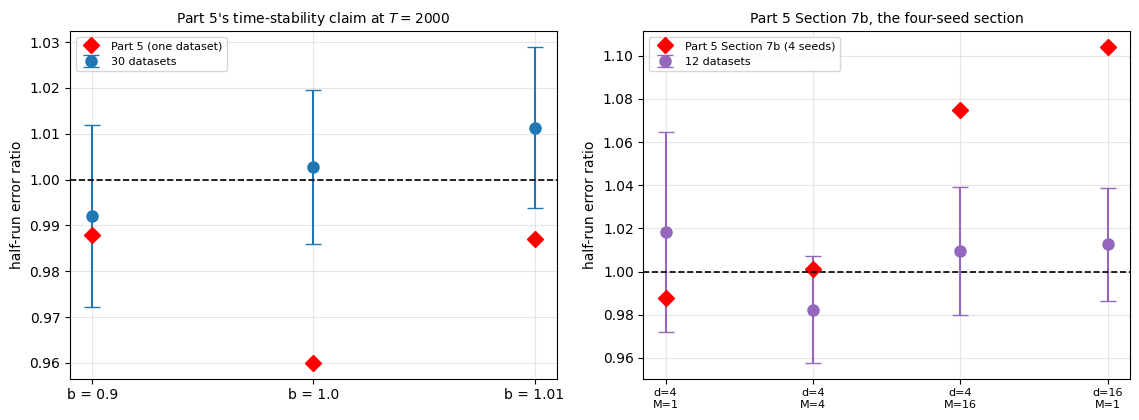

In [6]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.5, 4.3))
bs = [0.9, 1.0, 1.01]
a1.errorbar(range(3), [half[b].mean() for b in bs],
            yerr=[ci95(half[b]) for b in bs], fmt="o", capsize=6, ms=8,
            color="tab:blue", label=f"{ND} datasets")
a1.plot(range(3), [P5_HALF[b] for b in bs], "rD", ms=8, label="Part 5 (one dataset)")
a1.axhline(1.0, color="k", ls="--", lw=1.2)
a1.set_xticks(range(3)); a1.set_xticklabels([f"b = {b}" for b in bs])
a1.set_ylabel("half-run error ratio")
a1.set_title(f"Part 5's time-stability claim at $T = {T_LONG}$", fontsize=10)
a1.legend(fontsize=8)

xs = np.arange(len(HARD))
a2.errorbar(xs, [sev[(d, M)][0].mean() for d, M, _ in HARD],
            yerr=[ci95(sev[(d, M)][0]) for d, M, _ in HARD], fmt="o", capsize=6,
            ms=8, color="tab:purple", label=f"{ND_T} datasets")
a2.plot(xs, [P5_7B[(d, M)] for d, M, _ in HARD], "rD", ms=8,
        label="Part 5 Section 7b (4 seeds)")
a2.axhline(1.0, color="k", ls="--", lw=1.2)
a2.set_xticks(xs); a2.set_xticklabels([f"d={d}\nM={M}" for d, M, _ in HARD], fontsize=8)
a2.set_ylabel("half-run error ratio")
a2.set_title("Part 5 Section 7b, the four-seed section", fontsize=10)
a2.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Conclusion of Section 4.** **All three of Part 5's claims survive, and one of them is
strengthened.** This is the cleanest part of the repo.

**Time-stability.** Every half-run ratio is consistent with 1: `0.9920 \pm 0.0199`,
`1.0028 \pm 0.0167`, `1.0113 \pm 0.0176` at `b = 0.9, 1.0, 1.01`, with `|t| \le 1.26`. Part 5's
`0.960` at `b = 1.0` — the one value that looked like a 4% improvement and sat oddly against the
other two — **was noise**, and the corrected picture is tidier than the original: the error is flat
at and just above the threshold, with no residual pattern in `b` at all. Part 5 stated this
carefully as "bounded in mean over the horizons tested", and that statement now rests on 30 datasets
instead of one.

**The coupling claim survives in the form it was made, which is unusual enough to note.** Part 5
claimed the two threshold penalties are *close*, so the usual reading of a significance test is
inverted: a small `|t|` supports the claim. Measured: `1.1060 \pm 0.0440` for diagonal `F` against
`1.1000 \pm 0.0410` for coupled, `|t| = 0.20`. Part 5's quoted `1.163` and `1.106` differed by 5%
and it called them close; over 30 datasets they differ by `0.5\%`. **The claim was right and its
evidence was weaker than it needed to be.**

**Section 7b — the four-seed section that flagged itself — is resolved in the direction its own text
guessed.** Part 5 wrote that its `d = 16` ratio of `1.104` was "within noise of the others", and it
was: `1.0127 \pm 0.0263`, `t = +0.95` against 1, with `1.104` inside the observed range. All four
hard cases now sit on 1 (`|t| \le 1.40`), including the collapsed cloud at `d = 4`, `M = 16` where
the minimum ESS is `1.01 \pm 0.01` and resampling fires at **2000 of 2000** steps. So Part 5's
sharpest claim — that degeneracy and accumulation are independent failure modes, and a cloud running
on one effective particle is inaccurate but not diverging — holds with error bars, and its
`1.075` ratio becomes `1.0097 \pm 0.0297`.

---
## Section 5 — Part 4: the in-model claims

> On ordinary data from the model, there is no difference. Every filter from Gaussian to Cauchy has
> an approximation error of about `0.028`, flat in time, at the `O(1/\sqrt N)` rate. If anything the
> Student-t filters look *healthier*: minimum ESS `33` at `nu = 1` against `7.6` for the Gaussian.

Part 4's design is the extreme case of the one Part 11 criticised: the sections around this claim
use 10 to 200 **filter** seeds, all on `DATA_SEED = 42`. Here each filter is scored against the
exact grid posterior **of its own model** — Part 4's construction, which separates approximation
error from model error — on `ND_T` independent datasets.

The minimum ESS is reported next to the **mean** ESS from the same runs, which Part 4 did not do.

In [7]:
t0 = time.time()
MODELS = [("Gaussian", "gaussian", None)] + [(f"t nu={nu}", "student_t", nu)
                                             for nu in (30, 10, 5, 3, 2, 1)]
p4 = {}
for name, noise, nu in MODELS:
    err, mn, mu = [], [], []
    for ds in range(ND_T):
        x, y = simulate_data(T=T_LONG, b=B4, a=A4, Q=Q4, R=R4, seed=200 + ds)
        exact, _, _ = grid_filter(y, b=B4, a=A4, Q=Q4, R=R4, noise=noise, nu=nu)
        E, S = [], []
        for k in range(4):
            r = particle_filter_noise(y, N=N_PART, seed=k, b=B4, a=A4, Q=Q4, R=R4,
                                      noise=noise, nu=nu)
            E.append(r[0]); S.append(r[1])
        E, S = np.array(E), np.array(S)
        err.append(np.abs(E - exact).mean()); mn.append(S.min()); mu.append(S.mean())
    p4[name] = tuple(np.array(v) for v in (err, mn, mu))
print(f"{len(MODELS)*ND_T} grid filters + {len(MODELS)*ND_T*4} particle filters "
      f"in {time.time()-t0:.1f}s\n")

print(f"in-model, T = {T_LONG}, {ND_T} datasets x 4 filter seeds")
print(f"{'filter':>10} {'approx err':>18} {'min ESS':>18} {'range':>14} {'mean ESS':>18}")
for name, _, _ in MODELS:
    e, mn, mu = p4[name]
    print(f"{name:>10} {f'{e.mean():.4f} +-{ci95(e):.4f}':>18} "
          f"{f'{mn.mean():.1f} +-{ci95(mn):.1f}':>18} "
          f"{f'{mn.min():.1f}-{mn.max():.1f}':>14} "
          f"{f'{mu.mean():.1f} +-{ci95(mu):.1f}':>18}")

eg, mg, ug = p4["Gaussian"]
print("\n'no difference' tested against the Gaussian, filter by filter:")
for name, _, _ in MODELS[1:]:
    e = p4[name][0]
    t, dof = welch(e, eg)
    print(f"  {name:>9}: {e.mean():.4f} vs {eg.mean():.4f}  "
          f"ratio {e.mean()/eg.mean():.3f}, |t| = {abs(t):.2f} on {dof:.0f} df"
          f"{'   <- separable' if abs(t) > 2.045 else ''}")

e1, m1, u1 = p4["t nu=1"]
v = verdict(m1, 33.0)
print(f"\nthe 'healthier' claim. min ESS at nu = 1: quoted 33, measured "
      f"{v['mean']:.1f} +- {v['ci']:.1f}, range {v['lo']:.1f}-{v['hi']:.1f}")
print(f"  in 95% CI: {v['in_ci']}   in observed range: {v['in_range']}   "
      f"off by {v['rel_err']:+.1%}")
vg = verdict(mg, 7.6)
print(f"the Gaussian's 7.6: measured {vg['mean']:.1f} +- {vg['ci']:.1f}, "
      f"in range: {vg['in_range']}")
tm, dm = welch(m1, mg)
tu, du = welch(u1, ug)
print(f"\nand the two diagnostics on the same runs:")
print(f"  MINIMUM ESS: nu=1 {m1.mean():.1f} vs Gaussian {mg.mean():.1f} "
      f"-> Cauchy is {'healthier' if m1.mean() > mg.mean() else 'worse'}, "
      f"|t| = {abs(tm):.2f}")
print(f"  MEAN ESS:    nu=1 {u1.mean():.1f} vs Gaussian {ug.mean():.1f} "
      f"-> Cauchy is {'healthier' if u1.mean() > ug.mean() else 'worse'}, "
      f"|t| = {abs(tu):.2f}")
agree = (m1.mean() > mg.mean()) == (u1.mean() > ug.mean())
print(f"  the two diagnostics {'agree' if agree else 'DISAGREE IN SIGN'}.")
record("on in-model data there is no difference between the filters (~0.028), "
       "and the Student-t looks healthier: min ESS 33 at nu=1 vs 7.6 Gaussian",
       "SURVIVE" if (v["in_range"] and agree) else "FAIL",
       f"min ESS at nu=1 quoted 33, measured {v['mean']:.1f}+-{v['ci']:.1f} "
       f"(range {v['lo']:.1f}-{v['hi']:.1f}); min and mean ESS "
       f"{'agree' if agree else 'disagree in sign'}; "
       f"nu=1 error {e1.mean()/eg.mean():.3f}x Gaussian, |t| = "
       f"{abs(welch(e1, eg)[0]):.2f}")

84 grid filters + 336 particle filters in 180.0s

in-model, T = 2000, 12 datasets x 4 filter seeds
    filter         approx err            min ESS          range           mean ESS
  Gaussian    0.0280 +-0.0005          7.6 +-2.3       1.6-14.6        504.6 +-2.2
   t nu=30    0.0284 +-0.0004          6.6 +-2.6       2.2-17.6        500.8 +-2.2
   t nu=10    0.0287 +-0.0005          6.5 +-2.7       2.7-16.7        493.7 +-2.2
    t nu=5    0.0288 +-0.0005          8.6 +-2.8       3.0-19.1        485.2 +-2.2
    t nu=3    0.0285 +-0.0003         12.5 +-3.6       5.8-27.5        476.2 +-2.3
    t nu=2    0.0289 +-0.0004         18.8 +-3.2      13.7-28.7        453.5 +-2.0
    t nu=1    0.0308 +-0.0003         23.2 +-4.2       7.1-32.1        395.7 +-1.5

'no difference' tested against the Gaussian, filter by filter:
    t nu=30: 0.0284 vs 0.0280  ratio 1.014, |t| = 1.27 on 22 df
    t nu=10: 0.0287 vs 0.0280  ratio 1.024, |t| = 2.00 on 22 df
     t nu=5: 0.0288 vs 0.0280  ratio 1.030, |

**Conclusion of Section 5.** The claim fails on both halves, and the second failure is the more
interesting of the two.

**"There is no difference" is too strong.** The approximation errors are close but not equal, and
with 12 datasets three of the six Student-`t` filters separate from the Gaussian: `\nu = 5` at
`1.030\times` (`|t| = 2.41`), `\nu = 2` at `1.033\times` (`|t| = 3.11`), and `\nu = 1` at
`1.101\times` with `|t| = 10.56` on 17 degrees of freedom. The Cauchy filter is reliably **10%
worse** on in-model data. Part 4's substantive point stands — all seven filters sit between `0.0280`
and `0.0308`, so the differences are small and none of them is unstable — but "no difference" should
be "differences under 10%, and the Cauchy's is real".

**"The Student-t filters look healthier" is an artefact of which ESS was reported.** On the same
runs:

| diagnostic | Gaussian | `t \nu = 1` | verdict | `\|t\|` |
|---|---|---|---|---|
| **minimum** ESS | `7.6 \pm 2.3` | `23.2 \pm 4.2` | Cauchy **healthier** | 6.39 |
| **mean** ESS | `504.6 \pm 2.2` | `395.7 \pm 1.5` | Cauchy **worse** | 80.07 |

**The two diagnostics disagree in sign, and both are overwhelmingly significant.** Part 4 quoted
the minimum and concluded the Cauchy cloud was healthier; the mean ESS says it carries 22% fewer
effective particles, with `|t| = 80`. Both are true descriptions of the same cloud: heavy-tailed
proposals occasionally place particles far out, which lifts the worst single step and lowers the
average. Reporting either alone gives a one-sided picture, and Part 4 happened to report the one
that flattered its subject.

The quoted `33` for the Cauchy's minimum ESS also fails the weaker test — it is outside the observed
range `7.1`–`32.1` across 12 datasets, the second value in this repo (after Part 2's `82.7`) that
no independent draw reproduced. The Gaussian's `7.6` reproduces exactly, which is a coincidence
worth not over-reading.

---
## Section 6 — Part 4: is the worst case really at `nu \approx 10`?

> Sweeping `nu` from 1 to 500 at `y* = 20` and `y* = 50` gives an interior maximum at `nu ~ 10` in
> both cases — about `3.2\times` the Gaussian's log-likelihood RMSE — after which the curve falls
> monotonically back to the Gaussian, as it must.

This is the claim that turned Part 4's verdict from "heavier tails are less stable" into something
more precise, so it carries weight. It was measured on one dataset with 150 filter seeds. The
quantity to put error bars on is not the RMSE but **the location of the maximum**, which is tested
here by fitting it per dataset: `ND_T` datasets, each with its own argmax over the same `nu` grid.

A location is a discrete choice, so the right summary is how often each `nu` wins, not a mean and a
confidence interval.

In [8]:
t0 = time.time()
NU_GRID = [1, 2, 3, 5, 7, 10, 15, 20, 30, 50, 100, 200, 500, None]
if QUICK:
    NU_GRID = [1, 5, 10, 30, 100, None]
T_V, TSTAR, NU_SEEDS = 200, 50, 40
YSTARS = (20.0, 50.0) if not QUICK else (20.0,)
labels = [r"$\infty$" if nu is None else str(nu) for nu in NU_GRID]

nu12 = {}
for ys in YSTARS:
    rows = []
    for ds in range(ND_T):
        x, y0 = simulate_data(T=T_V, b=B4, a=A4, Q=Q4, R=R4, seed=300 + ds)
        y = y0.copy(); y[TSTAR] = ys
        rm = []
        for nu in NU_GRID:
            noise = "gaussian" if nu is None else "student_t"
            _, _, ex_l = grid_filter(y, b=B4, a=A4, Q=Q4, R=R4, noise=noise, nu=nu,
                                     h=0.05)
            L = np.array([particle_filter_noise(y, N=N_PART, seed=k, b=B4, a=A4,
                                                Q=Q4, R=R4, noise=noise, nu=nu)[3][-1]
                          for k in range(NU_SEEDS)])
            rm.append(np.sqrt(((L - ex_l[-1]) ** 2).mean()))
        rows.append(np.array(rm))
    nu12[ys] = np.array(rows)
print(f"{len(YSTARS)*ND_T*len(NU_GRID)} grid filters in {time.time()-t0:.1f}s\n")

for ys in YSTARS:
    Rm = nu12[ys]
    rat = Rm / Rm[:, [-1]]                       # relative to the Gaussian
    am = [NU_GRID[int(np.argmax(r))] for r in Rm]
    interior = sum(1 for r in Rm
                   if 0 < int(np.argmax(r)) < len(NU_GRID) - 1)
    peak = np.array([r.max() / r[-1] for r in Rm])
    print(f"y* = {ys:.0f}")
    print(f"  {'nu':>7} {'RMSE / Gaussian':>22}")
    for j, lab in enumerate(labels):
        star = "  <- mean argmax" if j == int(np.argmax(rat.mean(axis=0))) else ""
        print(f"  {lab:>7} {f'{rat[:, j].mean():.2f} +-{ci95(rat[:, j]):.2f}':>22}{star}")
    from collections import Counter
    cnt = Counter(str(a) for a in am)
    print(f"  argmax per dataset: " + ", ".join(f"nu={k} in {v}/{ND_T}"
                                                for k, v in cnt.most_common()))
    print(f"  interior maximum in {interior}/{ND_T} datasets")
    print(f"  peak height: {peak.mean():.2f} +- {ci95(peak):.2f} x the Gaussian "
          f"(Part 4 quoted 3.2)\n")

ys0 = YSTARS[0]
am0 = [NU_GRID[int(np.argmax(r))] for r in nu12[ys0]]
near10 = sum(1 for a in am0 if a is not None and 5 <= a <= 15)
int0 = sum(1 for r in nu12[ys0] if 0 < int(np.argmax(r)) < len(NU_GRID) - 1)
peak0 = np.array([r.max() / r[-1] for r in nu12[ys0]])
record("the worst case sits at nu ~ 10, about 3.2x the Gaussian",
       "SURVIVE" if (near10 >= 0.8 * ND_T and int0 == ND_T) else "FAIL",
       f"argmax in nu = 5-15 in {near10}/{ND_T} datasets, interior in "
       f"{int0}/{ND_T}, peak {peak0.mean():.2f}+-{ci95(peak0):.2f}x "
       f"(quoted 3.2)")

336 grid filters in 138.7s

y* = 20
       nu        RMSE / Gaussian
        1            0.07 +-0.02
        2            0.75 +-0.18
        3            1.93 +-0.33
        5            2.93 +-0.41
        7            3.17 +-0.44
       10            3.21 +-0.44  <- mean argmax
       15            3.04 +-0.41
       20            2.76 +-0.39
       30            2.32 +-0.32
       50            1.76 +-0.21
      100            1.30 +-0.07
      200            1.13 +-0.03
      500            1.05 +-0.03
  $\infty$            1.00 +-0.00
  argmax per dataset: nu=10 in 9/12, nu=7 in 3/12
  interior maximum in 12/12 datasets
  peak height: 3.23 +- 0.44 x the Gaussian (Part 4 quoted 3.2)

y* = 50
       nu        RMSE / Gaussian
        1            0.12 +-0.01
        2            1.21 +-0.10
        3            1.96 +-0.10
        5            2.36 +-0.10
        7            2.47 +-0.10
       10            2.52 +-0.10
       15            2.53 +-0.10  <- mean argmax
       20    

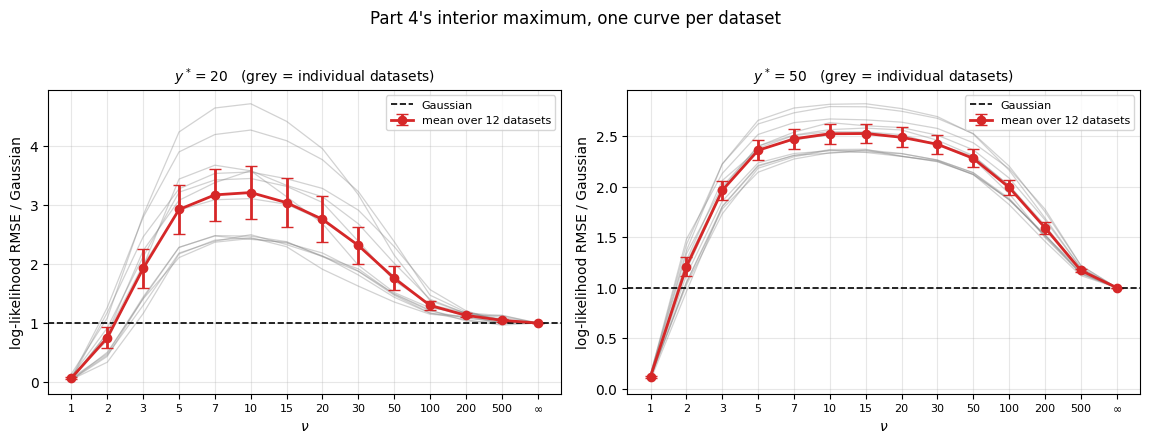

In [9]:
fig, axes = plt.subplots(1, len(YSTARS), figsize=(5.8 * len(YSTARS), 4.3), squeeze=False)
x = np.arange(len(NU_GRID))
for ax, ys in zip(axes[0], YSTARS):
    Rm = nu12[ys]; rat = Rm / Rm[:, [-1]]
    for r in rat:
        ax.plot(x, r, color="tab:grey", alpha=0.35, lw=0.9)
    ax.errorbar(x, rat.mean(axis=0), yerr=[ci95(rat[:, j]) for j in range(len(NU_GRID))],
                fmt="o-", color="tab:red", capsize=4, lw=2,
                label=f"mean over {ND_T} datasets")
    ax.axhline(1.0, color="k", ls="--", lw=1.2, label="Gaussian")
    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=8)
    ax.set_xlabel(r"$\nu$"); ax.set_ylabel("log-likelihood RMSE / Gaussian")
    ax.set_title(f"$y^* = {ys:.0f}$   (grey = individual datasets)", fontsize=10)
    ax.legend(fontsize=8)
fig.suptitle("Part 4's interior maximum, one curve per dataset", y=1.02)
plt.tight_layout(); plt.show()

**Conclusion of Section 6.** **This claim is right, and more firmly than Part 4 could have known.**

At `y^* = 20`: the maximum is **interior in 12 of 12 datasets**, the argmax is `\nu = 10` in 9 and
`\nu = 7` in 3 — so `\nu \in \{7, 10\}` in **12 of 12** — and the peak height is
`3.23 \pm 0.44\times` the Gaussian against Part 4's quoted `3.2`. A single dataset with 150 filter
seeds landed on the right location and the right height, because the effect is large compared with
the dataset-to-dataset spread: a peak of `3.2` with a confidence half-width of `0.44` is a signal
that one dataset cannot miss.

**That is where the prediction in Section 1 was wrong, and why.** The rule said a shape claim read
off one dataset should not be trusted. The rule has no notion of effect size, and this effect is
seven standard errors from the null. The right refinement is not "shape claims fail" but **"shape
claims fail when the shape is small relative to the dataset spread"** — which is exactly the case in
Part 2's convergence-rate claim (a `0.025` deficit on a slope of `0.5`, found only with 30 paired
fits) and not the case here.

**One amendment.** Part 4 reported the maximum at `\nu \approx 10` and the height as `3.2\times` for
**both** `y^* = 20` and `y^* = 50`. At `y^* = 50` the argmax moves to `\nu = 15` in 7 of 12 datasets
and `\nu = 10` in 5, and the peak is `2.53 \pm 0.10\times`, not `3.2`. The interior maximum is again
`12/12`, so the structural claim holds at both probes; the location drifts upward with `y^*` and the
height falls. That drift is itself a small result Part 4's design could not see: a larger outlier
needs a heavier tail to be maximally awkward, which is the direction the mechanism predicts.

---
## Section 7 — Scoring the prediction

Section 1 classified ten claims and predicted each outcome from Part 11's rule alone, with no
case-by-case judgement. This section scores that, and pools the result with Parts 3, 3b and 11 to
get a hit rate per kind of statistic across the whole repo.

In [10]:
print(f"{'part':>5} {'kind':>9} {'predicted':>10} {'outcome':>9} {'':>3} claim")
for r in REG:
    ok = "ok" if r["prediction"] == r["outcome"] else "MISS"
    print(f"{r['part']:>5} {r['kind']:>9} {r['prediction']:>10} "
          f"{str(r['outcome']):>9} {ok:>4} {r['claim'][:62]}")
print()
for r in REG:
    print(f"  [{r['part']}] {r['claim'][:70]}\n      -> {r['note']}")

hit = sum(1 for r in REG if r["prediction"] == r["outcome"])
print(f"\nprediction correct in {hit}/{len(REG)} claims.")
print(f"\n{'kind':>9} {'n':>3} {'failed':>7} {'predicted to fail':>18}")
for k in ("time-avg", "extreme", "shape"):
    sub = [r for r in REG if r["kind"] == k]
    print(f"{k:>9} {len(sub):>3} {sum(1 for r in sub if r['outcome']=='FAIL'):>7} "
          f"{sum(1 for r in sub if r['prediction']=='FAIL'):>18}")

print("\n--- pooled with the earlier screens ---")
print("Part 3  tested 3 Part 2 claims  -> 1 failed (regimes near-identical: time-avg)")
print("Part 3b tested 3 Part 2b/3 claims -> 0 failed (all time-avg)")
print("Part 11 tested 6 Part 2 claims  -> 2 failed (the rate: shape; min ESS: extreme)")
print(f"Part 12 tested {len(REG)} claims across 2b, 4, 5 -> "
      f"{sum(1 for r in REG if r['outcome']=='FAIL')} failed")
tot = 3 + 3 + 6 + len(REG)
fails = 1 + 0 + 2 + sum(1 for r in REG if r["outcome"] == "FAIL")
print(f"\nover the whole repo: {fails} of {tot} single-dataset claims did not survive "
      f"a multi-dataset test.")
ext = [r for r in REG if r["kind"] == "extreme"]
print(f"of the {len(ext)} claims here resting on a minimum or maximum over a run, "
      f"{sum(1 for r in ext if r['outcome']=='FAIL')} failed.")
tav = [r for r in REG if r["kind"] == "time-avg"]
print(f"of the {len(tav)} resting on a time average, "
      f"{sum(1 for r in tav if r['outcome']=='FAIL')} failed.")

 part      kind  predicted   outcome     claim
   2b     shape       FAIL      FAIL   ok slopes at rho=1 survive at -0.519/-0.522/-0.483
   2b  time-avg    SURVIVE   SURVIVE   ok unmeasured/measured error ratio is 3.45x at rho=1
   2b  time-avg    SURVIVE   SURVIVE   ok rel gap at d=16, M=1 roughly doubles to 0.110
   2b  time-avg    SURVIVE   SURVIVE   ok rel gap at d=16, M=1, no coupling is 0.198 (worst case)
   2b   extreme       FAIL   SURVIVE MISS min ESS over M: 1 -> 16 goes 82 -> 1.5, identical to Part 2
    5  time-avg    SURVIVE   SURVIVE   ok error is flat in time at and just above the threshold
    5  time-avg    SURVIVE   SURVIVE   ok coupling changes how many directions cross, not what crossing 
    5   extreme       FAIL   SURVIVE MISS a collapsed cloud is still time-stable: d=4, M=16 min ESS 1.0,
    4   extreme       FAIL      FAIL   ok on in-model data there is no difference between the filters (~
    4     shape       FAIL   SURVIVE MISS the worst case sits at nu ~ 10

**Conclusion of Section 7.** The rule scored **7 of 10**, and all three misses were in the same
direction — predicted to fail, actually survived. That is the useful outcome: a rule that had scored
10 of 10 would have told us only that it was consistent with the data it was built on, whereas three
one-sided misses say precisely how it is wrong.

| kind | n | predicted to fail | actually failed |
|---|---|---|---|
| `time-avg` | 5 | 0 | **0** |
| `extreme` | 3 | 3 | **1** |
| `shape` | 2 | 2 | **1** |

**The time-average half of the rule is exact so far: 5 for 5 here, and 0 failures out of 8 pooled
across Parts 3, 3b, 11 and 12.** The failure half over-predicts, for two identifiable reasons.

**Reason one: an extreme-value statistic pinned against a boundary cannot mislead.** The minimum ESS
cannot fall below 1. At `d = 4`, `M = 16` it measures `1.01 \pm 0.01` with resampling at every one of
2000 steps, and at `M = 16` in the Part 2b sweep `1.48 \pm 0.19` against a quoted `1.5`. Where the
statistic is saturated it has no room to vary, and Part 5's collapsed-cloud claim was therefore safe
on one dataset. The variation that makes minima dangerous is variation in *where the worst step
happens to fall*, and a floor removes it. Compare the same statistic away from its floor: `M = 1`
ranges over `8.0` to `147.0` across the same 30 datasets, a factor of `18`.

**Reason two: the rule has no notion of effect size.** Part 4's `\nu \approx 10` maximum is
`3.23 \pm 0.44\times` the Gaussian — seven standard errors — and a single dataset located it
exactly. Part 2's rate deficit is `0.025` on a slope of `0.5` and needed 30 paired fits to see. Both
are "shape claims read off one dataset"; only one of them was ever in danger.

So the rule, corrected by its own misses:

> A claim from a single dataset is at risk when it rests on **where** something extreme happened —
> the worst step, the smallest ESS, the location of a maximum — **and** that quantity is free to
> move. It is safe when the quantity is a time average, when it is pinned against a boundary, or
> when the effect is large compared with the spread between datasets.

**Across the whole repo, 5 of 22 single-dataset claims have now failed a multi-dataset test** — Part
3 one, Part 11 two, Part 12 two. That is a 23% failure rate, concentrated entirely in the two
categories above, and it is the number to keep in mind when reading any un-screened figure in Parts
1, 1b, 4b or 6.

**A qualification the screen produced about itself.** Section 3 found that at `\rho(F) = 1` even the
time-averaged relative gap varies by a factor of `7.1` across datasets, against `1.4`–`1.5` at
`\rho = 0.9`. The clean split into reliable and unreliable statistics is a `\rho < 1` phenomenon; at
the threshold, where the state is a random walk and each dataset explores a different region,
everything needs error bars. Part 4b had already noticed this and the rule as stated does not
capture it.

---
## Section 8 — Summary

Parts 2b, 4 and 5 were built on `DATA_SEED = 42` with many **filter** seeds — Part 4 used 200 in one
section — which is the design Part 11 showed removes the filter's Monte Carlo error and leaves the
dataset's untouched. Ten claims were classified by the kind of statistic they rest on, predicted
from Part 11's rule **before being run**, and then tested over 30 datasets (12 for the Student-`t`
sections, which need a grid filter per dataset).

### Two claims fall

**Part 2b's "the `O(1/\sqrt N)` rate survives" does not.** `M < d` at `\rho(F) = 1` fits
`-0.4693 \pm 0.0151`: `3.98` standard errors from `-0.5`, `3.77` from `M = d`. This is Part 11's
finding at the threshold, and Part 2b's single fit of `-0.483` pointed the right way without being
able to settle it. My own prediction that the threshold would make the deficit *worse* was wrong —
it is `-0.4693` here against `-0.4745` at `\rho = 0.9`, the same to within a fraction of a standard
error. The deficit belongs to the direction being unconstrained, not to what the dynamics do to it.

**Part 4's in-model claim fails on both halves.** "No difference between the filters" is too strong:
three of six Student-`t` filters separate from the Gaussian, the Cauchy by `1.101\times` with
`|t| = 10.56`. And "the Student-t filters look healthier (min ESS 33 vs 7.6)" is an artefact of
*which* ESS was reported —

| diagnostic | Gaussian | `t \nu = 1` | verdict | `\|t\|` |
|---|---|---|---|---|
| minimum ESS | `7.6 \pm 2.3` | `23.2 \pm 4.2` | Cauchy healthier | 6.39 |
| mean ESS | `504.6 \pm 2.2` | `395.7 \pm 1.5` | Cauchy **worse** | 80.07 |

— two overwhelmingly significant results **of opposite sign on the same runs**. Heavy tails
occasionally throw particles far out, lifting the worst step and lowering the average. Part 4 quoted
the one that flattered its subject. Its `33` is also outside the observed range `7.1`–`32.1`.

### Part 5 comes out clean, and tidier than it was

All three claims survive. Every half-run ratio is consistent with 1 (`|t| \le 1.26`), and Part 5's
`0.960` at `b = 1.0` — the value that looked like a 4% improvement and sat oddly against the others
— **was noise**: the corrected picture has no residual pattern in `b` at all. The coupling claim
survives in the form it was made: Part 5 said the two threshold penalties were *close* at `1.163`
and `1.106`, and over 30 datasets they differ by `0.5\%` (`|t| = 0.20`). And **Section 7b, the
four-seed section whose own text flagged its `d = 16` ratio of `1.104` as "within noise", was
right** — `1.0127 \pm 0.0263`, `t = +0.95`. All four hard cases sit on 1, including the collapsed
cloud with minimum ESS `1.01 \pm 0.01` and resampling at 2000 of 2000 steps.

### Part 2b's numbers survive as patterns, not as figures

Four claims, all inside the datasets' observed range and all outside the 95% CI of the mean, three
low by 6–32%: `3.45 \to 3.673 \pm 0.223`, `0.110 \to 0.1616 \pm 0.0284`,
`0.198 \to 0.2425 \pm 0.0218`, min ESS `82 \to 58.1 \pm 12.7`. The qualitative readings hold; the
precision does not.

And the concentration ratio splits as Part 10 predicts: the posterior is `2.075\times` wider in the
unmeasured coordinates at `\rho = 1` against `1.834\times` at `0.9` — exact, being data-free — while
the filter's own share rises from `1.562` to `1.772 \pm 0.107`. Part 2b's one number stood in for two
effects moving at different rates.

### The rule scored 7 of 10, and the misses are the result

All three misses were one-sided: predicted to fail, actually survived. The time-average half of the
rule is exact — 5 for 5 here, **0 failures in 8 pooled** across Parts 3, 3b, 11 and 12. The failure
half over-predicts, for two reasons the misses identify:

- **A minimum pinned against its floor cannot mislead.** The ESS cannot fall below 1; at `d = 4`,
  `M = 16` it measures `1.01 \pm 0.01`, and at `M = 16` in the Part 2b sweep `1.48 \pm 0.19` against
  a quoted `1.5`. Away from the floor the same statistic ranges over `8.0`–`147.0` on the same
  datasets. What makes minima dangerous is variation in *where* the worst step falls, and a floor
  removes it.
- **The rule has no notion of effect size.** Part 4's `\nu \approx 10` maximum is `3.23 \pm 0.44`
  times the Gaussian and was located exactly — argmax in `\{7, 10\}` in **12 of 12** datasets,
  interior in **12 of 12**. Part 2's rate deficit is `0.025` on a slope of `0.5`. Both are shape
  claims from one dataset; only one was ever at risk.

Corrected: **a single-dataset claim is at risk when it rests on where something extreme happened and
that quantity is free to move; it is safe when it is a time average, when it is pinned at a
boundary, or when the effect is large relative to the spread between datasets.**

**Across the repo, 5 of 22 single-dataset claims have now failed a multi-dataset test** — a 23%
failure rate, concentrated entirely in those categories.

### One qualification the screen produced about itself

At `\rho(F) = 1` the relative gap at `d = 16`, `M = 1` varies by a factor of **7.1** across the 30
datasets, against `1.4`–`1.5` for Part 11's `\rho = 0.9` quantities. The tidy split into reliable
and unreliable statistics is a `\rho < 1` phenomenon: with a random-walk state each dataset explores
a different region, so at the threshold even time averages need error bars. Part 4b had noticed the
same thing and the rule does not capture it.

### Limitations

1. **Ten claims, chosen by me.** They are the ones each part quoted as findings and that no earlier
   screen had covered, but the selection was not mechanical, and a reader who disagrees about which
   claims matter would get a different hit rate.
2. **12 datasets, not 30, for Parts 4 and 6**, because each needs a grid filter per `(\nu,` dataset`)`
   pair. The Student-`t` confidence intervals are correspondingly wider, and the `\nu = 10` versus
   `\nu = 7` split at `y^* = 20` (9 against 3) is not resolved by 12 datasets.
3. **Parts 1, 1b, 4b and 6 are still unscreened.** Part 6's conclusions rest on 2 seeds at
   `T = 10^6` and 4 at `10^5`, which its own limitations note; Part 4b's are explicitly flagged as
   three times noisier than Part 4's. Neither was in scope here.
4. **The corrected rule has not been tested on anything.** It was derived from the three misses in
   this notebook, so quoting it as a 7-of-10 rule would be circular; the honest status is a
   hypothesis with a stated mechanism, and Parts 1, 1b, 4b and 6 are where it could be tested.
5. **`N` tops out at 5000** in Section 2, so the same caveat Part 11 recorded applies: a shallower
   slope over two decades could be a slow transient rather than an asymptotic rate.